# Set Up Data

```
# This is formatted as code
```



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.optimize import least_squares
from scipy.stats import chi2

In [ ]:
# from Jens' email on 8/5/2013 (yahoo account):
c1q_SM=-0.71921
c2q_SM=-0.09493

In [ ]:
hallc_syst=0.012
hallc_split=0.2 # fraction of time spent at lower angle
hallc_stat_loq=np.sqrt(hallc_split/0.5)
hallc_stat_hiq=np.sqrt((1-hallc_split)/0.5)

In [ ]:
solid11_syst=0.0057 # 0.4% polarimetry, 0.2% Q2, rad corr 0.2%, event recon 0.2%, PDF 0.2%
# solid11_stat=np.sqrt(2.)
solid11_stat=1.0
solid11_corr=np.sqrt(0.004*0.004+0.002*0.002)/solid11_syst


solid11_lite_stat=np.sqrt(2.)
solid11_lite_syst=np.sqrt(0.004*0.004+0.002*0.002+0.002*0.002 * 2 + 0.002*0.002)
solid11_lite_corr=np.sqrt(0.004*0.004+0.002*0.002)/solid11_lite_syst

In [ ]:
data_pvdis6 = [
    {
        "name": "PVDIS6",
        "A": np.array([-91.1, -160.8]),
        "stat": np.array([3.1, 6.4]),
        "syst": np.array([3.0, 3.1]),
        "x": np.array([0.241, 0.295]),
        "Q2": np.array([1.085, 1.901]),

        # A_i = coeff[i, 0]*X + coeff[i, 1]*Y
        "coeff": np.array([
            [115.63, 115.63 * 0.348],
            [202.2,  202.2  * 0.594],
        ]),

        # Fraction of systematic variance correlated
        # between measurements within this dataset
        "f_corr": 1.0,
    }
]

# Vertical band for elastic + Cs APV used in PVDIS6
X_el = -0.70341
X_el_err = 0.16048E-01  # 0.016048

data_el = {
    "name": "EL",
    "A": np.array([X_el]),
    "stat": np.array([0.0]),
    "syst": np.array([X_el_err]),
    "x": np.array([0.99]), # elastic, use 0.99 to avoid betaHT divergent
    "Q2": np.array([10000.]), # fix this later
    "coeff": np.array([
        [1.0, 0.0],  # constrains X only
    ]),
    "f_corr": 0.0,
}

# Qweak
# from Nature paper and calculated:

C1u_qweak = -0.1874
C1u_qweak_err = 0.0022

C1d_qweak = 0.3389
C1d_qweak_err = 0.0025

rho_qweak = -0.9318  # Correlation coefficient

# Central value
X_qweak = 2 * C1u_qweak - C1d_qweak

# Uncertainty, including correlation
X_qweak_err = np.sqrt(
    4 * C1u_qweak_err**2
    + C1d_qweak_err**2
    - 4 * rho_qweak * C1u_qweak_err * C1d_qweak_err
)

data_qweak = {
    "name": "Qweak",
    "A": np.array([X_qweak]),
    "stat": np.array([0.0]),
    "syst": np.array([X_qweak_err]),
    "x": np.array([0.99]), # elastic, use 0.99 to avoid betaHT divergent
    "Q2": np.array([10000.]), # fix this later
    "coeff": np.array([
        [1.0, 0.0],  # constrains X only
    ]),
    "f_corr": 0.0,
}


# P2 expected
# read from
# D. Becker et al., Eur. Phys. J. A 54 (2018) 208, [1802.04759]
# (2C1u-C1d)proj = −0.7142 ± 0.00236

X_p2 = -0.7142
X_p2_err = 0.00236

data_p2 = {
    "name": "P2",
    "A": np.array([X_p2]),
    "stat": np.array([0.0]),
    "syst": np.array([X_p2_err]),
    "x": np.array([0.99]), # elastic, use 0.99 to avoid betaHT divergent
    "Q2": np.array([10000.]), # fix this later
    "coeff": np.array([
        [1.0, 0.0],  # constrains X only
    ]),
    "f_corr": 0.0,
}

print(data_el)
print(data_p2)

{'name': 'EL', 'A': array([-0.70341]), 'stat': array([0.]), 'syst': array([0.016048]), 'x': array([0.99]), 'Q2': array([10000.]), 'coeff': array([[1., 0.]]), 'f_corr': 0.0}
{'name': 'P2', 'A': array([-0.7142]), 'stat': array([0.]), 'syst': array([0.00236]), 'x': array([0.99]), 'Q2': array([10000.]), 'coeff': array([[1., 0.]]), 'f_corr': 0.0}


In [ ]:
def read_data_file(filename, name, f_corr=1.0, f_stat = 1.0, f_syst=0.0):
    """
    Read output rows formatted as:
    Eb, Ep, theta, x, Q2, rate, Apv, dApv, c1coeff, c2coeff

    Return a dataset dictionary compatible with fit_data_c1c2().
    Assumes dApv is statistical uncertainty.
    """

    rows = []

    with open(filename, "r") as f:
        for line in f:
            values = line.split()

            # Skip header and descriptive lines
            if len(values) != 12:
                continue

            try:
                rows.append([float(v) for v in values])
            except ValueError:
                continue

    if not rows:
        raise ValueError(f"No numerical data found in {filename}")

    data = np.asarray(rows, dtype=float)

    # Columns
    Eb, Ep, theta, Y, W, x, Q2, rate, Apv, dApv, c1coeff, c2coeff = data.T

    dApv_stat = dApv * f_stat
    dApv_syst = np.abs(Apv) * f_syst

    return {
        "name": name,
        "A": Apv,
        "stat": dApv_stat,
        "syst": dApv_syst,
        "Y": Y,
        "wmm": W,
        "x": x,
        "Q2": Q2,
        "rate": rate,
        # A_i = coeff[i, 0]*X + coeff[i, 1]*Y
        "coeff": np.column_stack([c1coeff, c2coeff]),
        "f_corr": f_corr,

        # Optional: preserve kinematic information
        # "x": x,
        # "Q2": Q2,
        # "rate": rate,
    }

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)


Mounted at /content/gdrive


In [ ]:
data_path='gdrive/MyDrive/Colab Notebooks/outfiles_pvdis_2026/'
data_pre='hallc_pvdis_'
# data_pre='hallc_'
data_pre='hallc_bin_'

data_hms = {}

for i in range(1, 15):
    data_hms[i] = read_data_file(
        data_path + data_pre + f"hms1{i:02d}.dat",
        name=f"HMS {i:02d}",
        f_stat=hallc_stat_loq,
        f_syst=hallc_syst,
    )

data_shms = {}

for i in range(1, 15):
    data_shms[i] = read_data_file(
        data_path + data_pre + f"shms1{i:02d}.dat",
        name=f"HMS {i:02d}",
        f_stat=hallc_stat_loq,
        f_syst=hallc_syst,
    )

In [ ]:
data_hrsl1 = read_data_file(
    data_path+"halla_hrsl1.dat",
    name="HRS-L 12.9 deg, 3.66 GeV",
    # f_syst=3.0/91.1,
    f_syst=0.005,
)

data_hrsl2 = read_data_file(
    data_path+"halla_hrsl2.dat",
    name="HRS-L 20.0 deg, 2.63 GeV",
    # f_syst=3.1/160.8,
    f_syst=0.005,
)

data_hrsr1 = read_data_file(
    data_path+"halla_hrsr1.dat",
    name="HRS-R 20.0 deg, 2.63 GeV",
    # f_syst=3.1/160.8,
    f_syst=0.005,
)

data_hrsr2 = read_data_file(
    data_path+"halla_hrsr2.dat",
    name="HRS-L 20.0 deg, 2.63 GeV",
    # f_syst=3.1/160.8,
    f_syst=0.005,
)


In [ ]:
data_solid11 = read_data_file(
    data_path+"solid11.dat",
    name="SoLID 11 GeV, 120 days",
    f_syst=solid11_syst,
    f_stat=solid11_stat,
    f_corr=solid11_corr,
)

In [ ]:
def read_data_file_xq2(filename, name, f_corr=1.0, f_stat = 1.0, f_syst=0.0):
    """
    Read output rows formatted as:
    x, Q2, Apv, dApv, c1coeff, c2coeff

    Return a dataset dictionary compatible with fit_data_c1c2().
    Assumes dApv is statistical uncertainty.
    """

    rows = []

    with open(filename, "r") as f:
      next(f)  # skip the header line

      for line in f:
        values = line.strip().split(",")

        if len(values) != 6:
            continue

        try:
            rows.append([float(v) for v in values])
        except ValueError:
            continue

    if not rows:
        raise ValueError(f"No numerical data found in {filename}")

    data = np.asarray(rows, dtype=float)

    # Columns
    x, Q2, Apv, dApv, c1coeff, c2coeff = data.T

    dApv_stat = dApv * f_stat
    dApv_syst = np.abs(Apv) * f_syst

    return {
        "name": name,
        "A": Apv,
        "stat": dApv_stat,
        "syst": dApv_syst,
        # "Y": Y,
        # "wmm": W,
        "x": x,
        "Q2": Q2,
        # "rate": rate,
        # A_i = coeff[i, 0]*X + coeff[i, 1]*Y
        "coeff": np.column_stack([c1coeff, c2coeff]),
        "f_corr": f_corr,

        # Optional: preserve kinematic information
        # "x": x,
        # "Q2": Q2,
        # "rate": rate,
    }

In [ ]:
data_solid11_2022 = read_data_file_xq2(
    data_path+"pvdis_11gev_CJ15nlo.csv",
    name="SoLID 11 GeV, 120 days",
    f_syst=solid11_syst,
    f_stat=solid11_stat,
    f_corr=solid11_corr,
)

data_solid11_lite = read_data_file_xq2(
    data_path+"pvdis_11gev_CJ15nlo.csv",
    name="SoLID 11 GeV, 60 days",
    f_syst=solid11_lite_syst,
    f_stat=solid11_lite_stat,
    f_corr=solid11_lite_corr,
)


# Define fitting function

In [ ]:
def fit_data_c1c2(
    data_sets,
    stat_scale=1.0,
    syst_scale=1.0,
    confidence_levels=(0.683,),
    name=None,
):
    """
    Fit X = 2*C1u - C1d and Y = 2*C2u - C2d.

    Parameters
    ----------
    data_sets : list of dict
        Each dataset contains name, A, stat, syst, coeff,
        and f_corr. See the input section above.

    stat_scale : float
        Multiplicative scale applied to all statistical errors.

    syst_scale : float
        Multiplicative scale applied to all systematic errors.

    confidence_levels : tuple
        Joint confidence levels for the fitted ellipse.

    Returns
    -------
    result : dict
        Best-fit parameters, covariance matrix, parameter errors,
        correlation, chi-square, and ellipse geometry.
    """

    if stat_scale <= 0 or syst_scale <= 0:
        raise ValueError("Uncertainty scale factors must be positive.")

    # --------------------------------------------------------
    # Build the combined design matrix, data vector,
    # and block-diagonal measurement covariance matrix.
    # --------------------------------------------------------
    A_all = []
    coeff_all = []
    covariance_blocks = []

    for ds in data_sets:
        A = np.asarray(ds["A"], dtype=float)
        stat = np.asarray(ds["stat"], dtype=float) * stat_scale

        syst = np.asarray(ds["syst"], dtype=float) * syst_scale
        coeff = np.asarray(ds["coeff"], dtype=float)
        f = float(ds["f_corr"])

        n = len(A)

        if not (len(stat) == len(syst) == n):
            raise ValueError(
                f"Input array lengths do not match for {ds['name']}."
            )

        if coeff.shape != (n, 2):
            raise ValueError(
                f"{ds['name']}: coeff must have shape ({n}, 2)."
            )

        if np.any(stat < 0) or np.any(syst < 0):
            raise ValueError("Uncertainties cannot be negative.")

        if not 0.0 <= f <= 1.0:
            raise ValueError(
                f"{ds['name']}: f_corr must be between 0 and 1."
            )

        # Split systematic uncertainty by variance fraction.
        syst_corr = syst * np.sqrt(f)
        syst_uncorr = syst * np.sqrt(1.0 - f)

        # Statistical + uncorrelated systematic variance
        V = np.diag(stat**2 + syst_uncorr**2)

        # One fully correlated, same-sign systematic source
        V += np.outer(syst_corr, syst_corr)

        A_all.append(A)
        coeff_all.append(coeff)
        covariance_blocks.append(V)

    if not data_sets:
        raise ValueError("At least one dataset is required.")

    A_all = np.concatenate(A_all)
    M = np.vstack(coeff_all)

    # Independent datasets are treated as uncorrelated
    # with one another: assemble block-diagonal covariance.
    n_total = len(A_all)
    V = np.zeros((n_total, n_total))

    start = 0
    for block in covariance_blocks:
        n = block.shape[0]
        V[start:start+n, start:start+n] = block
        start += n

    # --------------------------------------------------------
    # Generalized least-squares fit
    # --------------------------------------------------------
    Vinv_M = np.linalg.solve(V, M)
    Vinv_A = np.linalg.solve(V, A_all)

    information = M.T @ Vinv_M

    if np.linalg.matrix_rank(information) < 2:
        raise ValueError(
            "The combined datasets do not independently constrain "
            "both X and Y. Add data with sensitivity to Y, or "
            "introduce an external constraint."
        )

    cov = np.linalg.inv(information)
    params = cov @ (M.T @ Vinv_A)

    Xfit, Yfit = params
    Xerr, Yerr = np.sqrt(np.diag(cov))
    param_corr = cov[0, 1] / (Xerr * Yerr)

    residual = A_all - M @ params
    chi2_min = residual @ np.linalg.solve(V, residual)
    ndof = len(A_all) - 2

    # --------------------------------------------------------
    # Ellipse eigenvalues and orientation
    # --------------------------------------------------------
    eigenvalues, eigenvectors = np.linalg.eigh(cov)

    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    angle = np.degrees(np.arctan2(
        eigenvectors[1, 0], eigenvectors[0, 0]
    ))

    ellipses = {}

    for cl in confidence_levels:
        # 2-param joint ellipse - this gives larger ellipses than the line below (1.0)
        delta = chi2.ppf(cl, df=2)

        # Covariance / 1-sigma ellipse
        delta = 1.0

        # if using delta = 1.0, the caption should be:
        # The ellipses represent the 1σ parameter uncertainties obtained from the fit covariance matrix.
        # Or, even more precise:
        # The ellipses correspond to Δχ2 =1, with the projections onto the X and Y axes corresponding to the quoted 1σ uncertainties.

        # Semi-major and semi-minor axes
        a = np.sqrt(delta * eigenvalues[0])
        b = np.sqrt(delta * eigenvalues[1])

        ellipses[cl] = {
            "delta_chi2": delta,
            "semi_major": a,
            "semi_minor": b,
            "major_full_length": 2 * a,
            "minor_full_length": 2 * b,
        }

    # --------------------------------------------------------
    # Print results
    # --------------------------------------------------------
    print()
    print(name)
    print(f"Statistical uncertainty scale: {stat_scale:g}")
    print(f"Systematic uncertainty scale:  {syst_scale:g}")
    print()
    print(f"X = {Xfit:.6f} +/- {Xerr:.6f} (1 sigma)")
    print(f"Y = {Yfit:.6f} +/- {Yerr:.6f} (1 sigma)")
    print(f"Parameter correlation = {param_corr:.5f}")
    # print(f"chi2 = {chi2_min:.5f}")
    # print(f"ndof = {ndof}")

    # print("\nEllipse geometry:")
    print()
    print(f"Major-axis angle = {angle:.3f} degrees from +X")

    for cl, e in ellipses.items():
        print(
            f"{100*cl:.1f}% ellipse: "
            f"semi-major = {e['semi_major']:.6f}, "
            f"semi-minor = {e['semi_minor']:.6f}"
        )


    return {
        "params": params,
        "cov": cov,
        "Xerr": Xerr,
        "Yerr": Yerr,
        "param_corr": param_corr,
        "chi2": chi2_min,
        "ndof": ndof,
        "angle_deg": angle,
        "ellipses": ellipses,
    }

In [ ]:
def fit_data_c1c2_beta(
    data_sets,
    stat_scale=1.0,
    syst_scale=1.0,
    confidence_levels=(0.683,),
    name=None,
    beta_HT=None,
    beta_CSV=None,
    initial_guess=(1.0, 1.0, 0.0, 0.0),
):
    """
    Fit X = 2*C1u - C1d and Y = 2*C2u - C2d.

    Model:
      A_i = (c1_coeff_i*X + c2_coeff_i*Y)
            * (1 + beta_HT/((1-x_i)^3*Q2_i)
                 + beta_CSV*x_i^2)

    beta_HT / beta_CSV:
        None -> fit the parameter
        numeric value -> hold it fixed

    Each dataset must contain:
        name, A, stat, syst, coeff, f_corr, x, Q2

    Returns:
        Best-fit parameters, covariance matrices, errors,
        correlations, chi-square, and X-Y ellipse geometry.
    """

    if stat_scale <= 0 or syst_scale <= 0:
        raise ValueError("Uncertainty scale factors must be positive.")

    if not data_sets:
        raise ValueError("At least one dataset is required.")

    # --------------------------------------------------------
    # Build data vector, design matrix, and covariance blocks
    # --------------------------------------------------------
    A_list = []
    coeff_list = []
    x_list = []
    Q2_list = []
    covariance_blocks = []
    apply_beta_list = []

    for ds in data_sets:
        A = np.asarray(ds["A"], dtype=float)
        stat = np.asarray(ds["stat"], dtype=float) * stat_scale
        syst = np.asarray(ds["syst"], dtype=float) * syst_scale
        coeff = np.asarray(ds["coeff"], dtype=float)
        x = np.asarray(ds["x"], dtype=float)
        Q2 = np.asarray(ds["Q2"], dtype=float)
        f = float(ds["f_corr"])

        apply_beta_list.append(coeff[:, 1] != 0)

        n = len(A)

        if not (
            len(stat) == len(syst) == len(x) == len(Q2) == n
        ):
            raise ValueError(
                f"Input array lengths do not match for {ds['name']}."
            )

        if coeff.shape != (n, 2):
            raise ValueError(
                f"{ds['name']}: coeff must have shape ({n}, 2)."
            )

        if np.any(stat < 0) or np.any(syst < 0):
            raise ValueError("Uncertainties cannot be negative.")

        if not 0.0 <= f <= 1.0:
            raise ValueError(
                f"{ds['name']}: f_corr must be between 0 and 1."
            )

        if np.any((1.0 - x)**3 * Q2 == 0):
            raise ValueError(
                f"{ds['name']}: HT correction denominator is zero."
            )

        # Split systematic uncertainty into correlated and
        # uncorrelated components.
        syst_corr = syst * np.sqrt(f)
        syst_uncorr = syst * np.sqrt(1.0 - f)

        V_block = np.diag(stat**2 + syst_uncorr**2)
        V_block += np.outer(syst_corr, syst_corr)

        A_list.append(A)
        coeff_list.append(coeff)
        x_list.append(x)
        Q2_list.append(Q2)
        covariance_blocks.append(V_block)

    A_all = np.concatenate(A_list)
    M = np.vstack(coeff_list)
    x_all = np.concatenate(x_list)
    Q2_all = np.concatenate(Q2_list)
    apply_beta_all = np.concatenate(apply_beta_list)

    # Assemble block-diagonal covariance matrix.
    n_total = len(A_all)
    V = np.zeros((n_total, n_total))

    start = 0
    for block in covariance_blocks:
        n = block.shape[0]
        V[start:start+n, start:start+n] = block
        start += n

    try:
        L = np.linalg.cholesky(V)
    except np.linalg.LinAlgError as exc:
        raise ValueError(
            "Measurement covariance matrix is not positive definite."
        ) from exc

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------
    def predict(X, Y, bHT, bCSV):
      correction = np.ones_like(x_all)

      correction[apply_beta_all] += (
          bHT / ((1.0 - x_all[apply_beta_all])**3
               * Q2_all[apply_beta_all])
        + bCSV * x_all[apply_beta_all]**2
      )

      return (M @ np.array([X, Y])) * correction


    # --------------------------------------------------------
    # Choose free and fixed parameters
    # --------------------------------------------------------
    all_names = ["X", "Y", "beta_HT", "beta_CSV"]

    fixed = {
        "beta_HT": beta_HT,
        "beta_CSV": beta_CSV,
    }

    free_names = ["X", "Y"]

    if beta_HT is None:
        free_names.append("beta_HT")

    if beta_CSV is None:
        free_names.append("beta_CSV")

    if len(initial_guess) != 4:
        raise ValueError(
            "initial_guess must contain (X, Y, beta_HT, beta_CSV)."
        )

    guess = dict(zip(all_names, initial_guess))

    def unpack(p):
        values = {
            "X": None,
            "Y": None,
            "beta_HT": beta_HT,
            "beta_CSV": beta_CSV,
        }

        for key, value in zip(free_names, p):
            values[key] = value

        return values

    def residuals(p):
        q = unpack(p)

        prediction = predict(
            q["X"],
            q["Y"],
            q["beta_HT"],
            q["beta_CSV"],
        )

        # Whiten residuals using the full measurement covariance.
        return np.linalg.solve(L, A_all - prediction)

    p0 = np.array([guess[k] for k in free_names], dtype=float)

    # --------------------------------------------------------
    # Nonlinear least-squares fit
    # --------------------------------------------------------
    fit = least_squares(residuals, p0)

    if not fit.success:
        raise RuntimeError(f"Fit failed: {fit.message}")

    fitted = unpack(fit.x)
    residual = residuals(fit.x)

    chi2_min = float(residual @ residual)
    ndof = len(A_all) - len(free_names)

    # --------------------------------------------------------
    # Parameter covariance and correlations
    # --------------------------------------------------------
    information = fit.jac.T @ fit.jac

    if np.linalg.matrix_rank(information) < len(free_names):
        raise ValueError(
            "Fit parameters are not independently constrained. "
            "The Jacobian is rank deficient."
        )

    cov_free = np.linalg.inv(information)
    errs_free = np.sqrt(np.diag(cov_free))

    corr_free = cov_free / np.outer(errs_free, errs_free)

    # Extract the X-Y covariance submatrix.
    ix = free_names.index("X")
    iy = free_names.index("Y")

    cov_xy = cov_free[np.ix_([ix, iy], [ix, iy])]

    Xerr, Yerr = np.sqrt(np.diag(cov_xy))
    param_corr = cov_xy[0, 1] / (Xerr * Yerr)

    # --------------------------------------------------------
    # X-Y ellipse eigenvalues and orientation
    # --------------------------------------------------------
    eigenvalues, eigenvectors = np.linalg.eigh(cov_xy)

    if np.any(eigenvalues < -1e-12):
        raise ValueError(
            "The fitted X-Y covariance is not positive semidefinite."
        )

    eigenvalues = np.maximum(eigenvalues, 0.0)

    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    angle = np.degrees(
        np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0])
    )

    ellipses = {}

    for cl in confidence_levels:
        # Joint confidence contour for two parameters - this gives larger ellipses than the line below (1.0)
        delta = chi2.ppf(cl, df=2)

        # Covariance / 1-sigma ellipse
        delta = 1.0

        a = np.sqrt(delta * eigenvalues[0])
        b = np.sqrt(delta * eigenvalues[1])

        ellipses[cl] = {
            "delta_chi2": delta,
            "semi_major": a,
            "semi_minor": b,
            "major_full_length": 2.0 * a,
            "minor_full_length": 2.0 * b,
        }

    # --------------------------------------------------------
    # Print results
    # --------------------------------------------------------
    print()
    print(name if name is not None else "Fit results")
    print(f"Statistical uncertainty scale: {stat_scale:g}")
    print(f"Systematic uncertainty scale:  {syst_scale:g}")
    print()

    for key in all_names:
        if key in free_names:
            idx = free_names.index(key)

            print(
                f"{key} = {fitted[key]:.6g} "
                f"+/- {errs_free[idx]:.6g} (1 sigma)"
            )
        else:
            print(f"{key} = {fitted[key]:.6g} (fixed)")

    print()
    print("Correlation matrix for free parameters:")
    print("Parameters:", ", ".join(free_names))
    print(np.array2string(corr_free, precision=5, suppress_small=True))

    print()
    print(f"X-Y correlation = {param_corr:.5f}")
    print(f"chi2 = {chi2_min:.5f}")
    print(f"ndof = {ndof}")
    print(f"Major-axis angle = {angle:.3f} degrees from +X")

    print()
    print("Ellipse geometry:")

    for cl, e in ellipses.items():
        print(
            f"{100*cl:.1f}% ellipse "
            f"(Delta chi2 = {e['delta_chi2']:.4f}): "
            f"semi-major = {e['semi_major']:.6g}, "
            f"semi-minor = {e['semi_minor']:.6g}"
        )

        print(
            f"    Full major axis = {e['major_full_length']:.6g}, "
            f"full minor axis = {e['minor_full_length']:.6g}"
        )

    # --------------------------------------------------------
    # Return results
    # --------------------------------------------------------
    return {
        "params": np.array([fitted[k] for k in all_names]),
        "param_names": all_names,
        "free_param_names": free_names,
        "fitted": fitted,
        "cov": cov_xy,
        "cov_full": cov_free,
        "corr_free": corr_free,
        "Xerr": Xerr,
        "Yerr": Yerr,
        "param_corr": param_corr,
        "chi2": chi2_min,
        "ndof": ndof,
        "angle_deg": angle,
        "ellipses": ellipses,
    }

# Fitting

## (C1, C2) fit

In [ ]:
data_sets_pvdis6 = data_pvdis6

result_pvdis6 = fit_data_c1c2(
    data_sets_pvdis6,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall A 6 GeV",
)

# Shift the central values
result_pvdis6["params"] = np.array([-0.77627,-0.014913])

data_sets_6gev = data_pvdis6 + [data_el]

result_6gev = fit_data_c1c2(
    data_sets_6gev,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall A 6 GeV + Elastic + Cs",
)
# Shift the central values
result_6gev["params"] = np.array([-0.70717,-0.14328]) # or -0.14603?

data_sets_6gev_qweak = data_pvdis6 + [data_el] + [data_qweak]

result_6gev_qweak = fit_data_c1c2(
    data_sets_6gev_qweak,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall A 6 GeV + El + Cs + Qweak",
)
# Shift the central values
result_6gev_qweak["params"] = np.array([-0.70717,-0.14328])

data_sets_6gev_qweak_p2 = data_pvdis6 + [data_el] + [data_qweak] + [data_p2]

result_6gev_qweak_p2 = fit_data_c1c2(
    data_sets_6gev_qweak_p2,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall A 6 GeV + El + Cs + Qweak + P2",
)
# Shift the central values
result_6gev_qweak_p2["params"] = np.array([-0.70717,-0.14328])

data_sets_hrs = [data_hrsl1,data_hrsl2,data_hrsr1,data_hrsr2]

result_6gev_hrs = fit_data_c1c2(
    data_sets_hrs,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall A HRS check",
)
result_6gev_hrs["params"] = np.array([-0.70717,-0.14328])



Hall A 6 GeV
Statistical uncertainty scale: 1
Systematic uncertainty scale:  1

X = -0.777397 +/- 0.088731 (1 sigma)
Y = -0.030059 +/- 0.174050 (1 sigma)
Parameter correlation = -0.94429

Major-axis angle = 116.225 degrees from +X
68.3% ellipse: semi-major = 0.193591, semi-minor = 0.026255

Hall A 6 GeV + Elastic + Cs
Statistical uncertainty scale: 1
Systematic uncertainty scale:  1

X = -0.705754 +/- 0.015792 (1 sigma)
Y = -0.162762 +/- 0.064319 (1 sigma)
Parameter correlation = -0.45478

Major-axis angle = 96.684 degrees from +X
68.3% ellipse: semi-major = 0.064738, semi-minor = 0.013973

Hall A 6 GeV + El + Cs + Qweak
Statistical uncertainty scale: 1
Systematic uncertainty scale:  1

X = -0.712460 +/- 0.006238 (1 sigma)
Y = -0.150340 +/- 0.058436 (1 sigma)
Parameter correlation = -0.19773

Major-axis angle = 91.223 degrees from +X
68.3% ellipse: semi-major = 0.058450, semi-minor = 0.006114

Hall A 6 GeV + El + Cs + Qweak + P2
Statistical uncertainty scale: 1
Systematic uncertainty 

In [ ]:
# Fitting SoLID

data_sets_solid11 = [data_solid11]

result_11gev_solid = fit_data_c1c2(
    data_sets_solid11,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Solid11",
)
result_11gev_solid["params"] = np.array([-0.70717,-0.14328])

result_11gev_solid_all = fit_data_c1c2(
    data_sets_solid11 + data_sets_6gev_qweak_p2,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Solid11 + Existing + P2",
)
result_11gev_solid_all["params"] = np.array([-0.70717,-0.14328])

data_sets_solid11_2022 = [data_solid11_2022]

result_11gev_solid_2022 = fit_data_c1c2(
    data_sets_solid11_2022,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Solid11 (2022)",
)
result_11gev_solid_2022["params"] = np.array([-0.70717,-0.14328])

result_11gev_solid_2022_all = fit_data_c1c2(
    data_sets_solid11_2022 + data_sets_6gev_qweak_p2,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Solid11 (2022) + Existing + P2",
)
result_11gev_solid_2022_all["params"] = np.array([-0.70717,-0.14328])

data_sets_solid11_lite = [data_solid11_lite]
result_11gev_solid_lite = fit_data_c1c2(
    data_sets_solid11_lite,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Solid11 Lite",
)
result_11gev_solid_lite["params"] = np.array([-0.70717,-0.14328])

result_11gev_solid_lite_all = fit_data_c1c2(
    data_sets_solid11_lite + data_sets_6gev_qweak_p2,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Solid11 Lite + Existing + P2",
)
result_11gev_solid_lite_all["params"] = np.array([-0.70717,-0.14328])



Solid11
Statistical uncertainty scale: 1
Systematic uncertainty scale:  1

X = -0.716663 +/- 0.020607 (1 sigma)
Y = -0.090004 +/- 0.023928 (1 sigma)
Parameter correlation = -0.97909

Major-axis angle = 130.645 degrees from +X
68.3% ellipse: semi-major = 0.031416, semi-minor = 0.003193

Solid11 + Existing + P2
Statistical uncertainty scale: 1
Systematic uncertainty scale:  1

X = -0.714069 +/- 0.002194 (1 sigma)
Y = -0.093343 +/- 0.005459 (1 sigma)
Parameter correlation = -0.45898

Major-axis angle = 101.875 degrees from +X
68.3% ellipse: semi-major = 0.005564, semi-minor = 0.001912

Solid11 (2022)
Statistical uncertainty scale: 1
Systematic uncertainty scale:  1

X = -0.726667 +/- 0.032263 (1 sigma)
Y = -0.108000 +/- 0.038949 (1 sigma)
Parameter correlation = -0.99064

Major-axis angle = 129.587 degrees from +X
68.3% ellipse: semi-major = 0.050462, semi-minor = 0.003399

Solid11 (2022) + Existing + P2
Statistical uncertainty scale: 1
Systematic uncertainty scale:  1

X = -0.714065 +/-

In [ ]:
data_set_hms = {}
results_11gev_hms = {}
results_11gev_hms_all = {}

for i in [1, 2]:
    for j in [3, 8]:
        key = 100*i+j

        data_set_hms[key] = [data_hms[i], data_hms[j]]

        results_11gev_hms[key] = fit_data_c1c2(
            data_set_hms[key],
            stat_scale=1.0,
            syst_scale=1.0,
            name=f"Hall C HMS{i}+{j}",
        )

        results_11gev_hms[key]["params"] = np.array([-0.70717,-0.14328])

        results_11gev_hms_all[key] = fit_data_c1c2(
            data_set_hms[key] + data_sets_6gev_qweak_p2,
            stat_scale=1.0,
            syst_scale=1.0,
            name=f"Hall C HMS{100+i}+{j} + Existing + P2",
        )
        results_11gev_hms_all[key]["params"] = np.array([-0.70717,-0.14328])



data_set_shms = {}
results_11gev_shms = {}
results_11gev_shms_all = {}

for i in [1, 2]:
    for j in [3, 8]:
        key = 10*i+j

        data_set_shms[key] = [data_shms[i], data_shms[j]]

        results_11gev_shms[key] = fit_data_c1c2(
            data_set_shms[key],
            stat_scale=1.0,
            syst_scale=1.0,
            name=f"Hall C SHMS{100+i}+{j}",
        )
        results_11gev_shms[key]["params"] = np.array([-0.70717,-0.14328])

        results_11gev_shms_all[key] = fit_data_c1c2(
            data_set_shms[key] + data_sets_6gev_qweak_p2,
            stat_scale=1.0,
            syst_scale=1.0,
            name=f"Hall C SHMS{100+i}+{j} + Existing + P2",
        )
        results_11gev_shms_all[key]["params"] = np.array([-0.70717,-0.14328])


data_sets_hms_loq = [data_hms[1],data_hms[2]]
data_sets_hms_hiq = [data_hms[3],data_hms[4],data_hms[5],data_hms[6],data_hms[7]]#,data_hms[8]]
data_sets_hms_hiq2 = [data_hms[9],data_hms[10],data_hms[11]]#,data_hms[12],data_hms[13],data_hms[14]]
data_sets_shms_loq = [data_shms[1],data_shms[2]]
data_sets_shms_hiq =[data_shms[3],data_shms[4],data_shms[5]]#,data_shms[6],data_shms[7]],data_shms[8]]
data_sets_shms_hiq2 = [data_shms[9],data_shms[10]]#,data_shms[11],data_shms[12],data_shms[13],data_shms[14]]

result_11gev_hms_loq = fit_data_c1c2(
    data_sets_hms_loq,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall C HMS 12.5 deg",
)
# Shift the central values
result_11gev_hms_loq["params"] = np.array([-0.70717,-0.14328])

result_11gev_hms_hiq = fit_data_c1c2(
    data_sets_hms_hiq,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall C HMS 28.0 deg",
)
# Shift the central values
result_11gev_hms_hiq["params"] = np.array([-0.70717,-0.14328])

result_11gev_hms_hiq2 = fit_data_c1c2(
    data_sets_hms_hiq2,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall C HMS 35.0 deg",
)
# Shift the central values
result_11gev_hms_hiq2["params"] = np.array([-0.70717,-0.14328])

result_11gev_shms_loq = fit_data_c1c2(
    data_sets_shms_loq,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall C SHMS 12.5 deg",
)
# Shift the central values
result_11gev_shms_loq["params"] = np.array([-0.70717,-0.14328])

result_11gev_shms_hiq = fit_data_c1c2(
    data_sets_shms_hiq,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall C SHMS 28.0 deg",
)
# Shift the central values
result_11gev_shms_hiq["params"] = np.array([-0.70717,-0.14328])

result_11gev_shms_hiq2 = fit_data_c1c2(
    data_sets_shms_hiq2,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall C SHMS 35.0 deg",
)
# Shift the central values
result_11gev_shms_hiq2["params"] = np.array([-0.70717,-0.14328])

result_11gev_hms_loq_all = fit_data_c1c2(
    data_sets_hms_loq + data_sets_6gev_qweak_p2,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall C HMS 12.5 deg + Existing + P2",
)
# Shift the central values
result_11gev_hms_loq["params"] = np.array([-0.70717,-0.14328])

result_11gev_hms_hiq_all = fit_data_c1c2(
    data_sets_hms_hiq + data_sets_6gev_qweak_p2,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall C HMS 28.0 deg + Existing + P2",
)
# Shift the central values
result_11gev_hms_hiq_all["params"] = np.array([-0.70717,-0.14328])

result_11gev_hms_hiq2_all = fit_data_c1c2(
    data_sets_hms_hiq2 + data_sets_6gev_qweak_p2,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall C HMS 35.0 deg + Existing + P2",
)
# Shift the central values
result_11gev_hms_hiq2_all["params"] = np.array([-0.70717,-0.14328])

result_11gev_shms_loq_all = fit_data_c1c2(
    data_sets_shms_loq + data_sets_6gev_qweak_p2,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall C SHMS 12.5 deg + Existing + P2",
)
# Shift the central values
result_11gev_shms_loq_all["params"] = np.array([-0.70717,-0.14328])

result_11gev_shms_hiq_all = fit_data_c1c2(
    data_sets_shms_hiq + data_sets_6gev_qweak_p2,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall C SHMS 28.0 deg + Existing + P2",
)
# Shift the central values
result_11gev_shms_hiq_all["params"] = np.array([-0.70717,-0.14328])

result_11gev_shms_hiq2_all = fit_data_c1c2(
    data_sets_shms_hiq2 + data_sets_6gev_qweak_p2,
    stat_scale=1.0,
    syst_scale=1.0,
    name="Hall C SHMS 35.0 deg + Existing + P2",
)
# Shift the central values
result_11gev_shms_hiq2_all["params"] = np.array([-0.70717,-0.14328])





Hall C HMS1+3
Statistical uncertainty scale: 1
Systematic uncertainty scale:  1

X = -0.716671 +/- 0.038569 (1 sigma)
Y = -0.089994 +/- 0.065626 (1 sigma)
Parameter correlation = -0.96825

Major-axis angle = 120.047 degrees from +X
68.3% ellipse: semi-major = 0.075660, semi-minor = 0.008363

Hall C HMS101+3 + Existing + P2
Statistical uncertainty scale: 1
Systematic uncertainty scale:  1

X = -0.714006 +/- 0.002204 (1 sigma)
Y = -0.098409 +/- 0.016191 (1 sigma)
Parameter correlation = -0.22634

Major-axis angle = 91.796 degrees from +X
68.3% ellipse: semi-major = 0.016199, semi-minor = 0.002145

Hall C HMS1+8
Statistical uncertainty scale: 1
Systematic uncertainty scale:  1

X = -0.716697 +/- 0.107172 (1 sigma)
Y = -0.089942 +/- 0.209529 (1 sigma)
Parameter correlation = -0.99520

Major-axis angle = 117.024 degrees from +X
68.3% ellipse: semi-major = 0.235162, semi-minor = 0.009340

Hall C HMS101+8 + Existing + P2
Statistical uncertainty scale: 1
Systematic uncertainty scale:  1

X = 

## (C1, C2, betaHT, betaCSV) fit

In [ ]:
fit_sets = {
    "hallc1": (
        data_sets_hms1 + data_sets_shms1,
        "Hall C HMS1 + SHMS1",
    ),
    "hallc2": (
        data_sets_hms2 + data_sets_shms2,
        "Hall C HMS2 + SHMS2",
    ),
    "hallc1_all": (
        data_sets_hms1 + data_sets_shms1 + data_sets_6gev_qweak_p2,
        "Hall C HMS1 + SHMS1 + Existing + P2",
    ),
    "hallc2_all": (
        data_sets_hms2 + data_sets_shms2 + data_sets_6gev_qweak_p2,
        "Hall C HMS2 + SHMS2 + Existing + P2",
    ),
    "solid11": (
        data_sets_solid11,
        "Solid11",
    ),
    "solid11_all": (
        data_sets_solid11 + data_sets_6gev_qweak_p2,
        "Solid11 + Existing + P2",
    ),
    "solid11_2022": (
        data_sets_solid11_2022,
        "Solid11 (2022)",
    ),
    "solid11_2022_all": (
        data_sets_solid11_2022 + data_sets_6gev_qweak_p2,
        "Solid11 (2022) + Existing + P2",
    ),
    "solid11_lite": (
        data_sets_solid11_lite,
        "Solid11 Lite",
    ),
    "solid11_lite_all": (
        data_sets_solid11_lite + data_sets_6gev_qweak_p2,
        "Solid11 Lite + Existing + P2",
    ),
}

In [ ]:
fit_configs = {
    "result1": {
        "beta_HT": 0.0,
        "beta_CSV": 0.0,
    },
    "result2": {
        "beta_HT": None,
        "beta_CSV": 0.0,
    },
    "result3": {
        "beta_HT": 0.0,
        "beta_CSV": None,
    },
    "result4": {
        "beta_HT": None,
        "beta_CSV": None,
    },
}

central_values = np.array([-0.70717, -0.14328])

results = {}

for config_name, beta_kwargs in fit_configs.items():
    results[config_name] = {}

    for key, (datasets, fit_name) in fit_sets.items():
        result = fit_data_c1c2_beta(
            datasets,
            stat_scale=1.0,
            syst_scale=1.0,
            beta_HT=beta_kwargs["beta_HT"],
            beta_CSV=beta_kwargs["beta_CSV"],
            initial_guess=(1.0, 1.0, 0.0, 0.0),
            name=f"{fit_name} ({config_name})",
        )

        # Shift the central values
        result["params"] = central_values.copy()

        results[config_name][key] = result

# Plotting

## 6 GeV

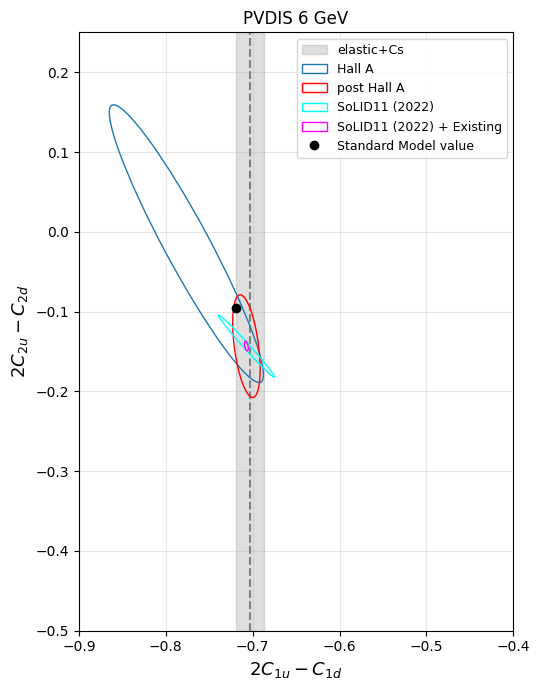

In [ ]:
# --------------------------------------------------
# Collect all fits to display
# --------------------------------------------------
results_to_plot = [
    (result_pvdis6, "Hall A", "tab:blue", False, "-"),
    (result_6gev, "post Hall A", "red", False, "-"),
    # (result_6gev_hrs,"HRS check (accp only + 0.5% syst)", "orange", False, "--"),
    # (result_11gev_hms_loq,"HMC 12.5 deg", "purple", False, "-"),
    # (result_11gev_hms_hiq,"HMC 28.0 deg", "magenta", False, "-"),
    # (result_11gev_shms_loq,"SHMS 12.5 deg", "green", False, "-"),
    # (result_11gev_shms_hiq,"SHMS 28.0 deg", "cyan", "-"),
    # (result_11gev_hallc1,"HallC1", "green", False, "--"),
    # (result_11gev_hallc1_all,"HallC1 + Existing + P2", "pink", True, "--"),
    (result_11gev_solid_2022,"SoLID11 (2022)", "cyan", False, "-"),
    (result_11gev_solid_2022_all,"SoLID11 (2022) + Existing", "magenta", False, "-"),
]

confidence_levels = [0.683]

fig, ax = plt.subplots(figsize=(5.5, 7))

ax.axvspan(
    X_el - X_el_err,
    X_el + X_el_err,
    color="gray",
    alpha=0.25,
    label=r"elastic+Cs"
)

ax.axvline(
    X_el,
    color="gray",
    linestyle="--",
    linewidth=1.5
)


# --------------------------------------------------
# Overlay all fitted ellipses
# --------------------------------------------------
for result, fit_label, color, fill, line in results_to_plot:

    Xfit, Yfit = result["params"]
    cov = result["cov"]
    angle = result["angle_deg"]
    ellipses = result["ellipses"]

    # # Best-fit point
    # ax.plot(
    #     Xfit, Yfit,
    #     marker="o",
    #     color=color,
    #     linestyle="none",
    #     label=f"{fit_label}: best fit",
    #     zorder=4,
    # )

    for cl in confidence_levels:
        e = ellipses[cl]

        ellipse = Ellipse(
            xy=(Xfit, Yfit),
            width=2 * e["semi_major"],
            height=2 * e["semi_minor"],
            angle=angle,
            fill=fill,
            edgecolor=color,
            facecolor=color,
            linestyle=line,
            linewidth=1,
            # label=f"{fit_label}: {100*cl:g}%",
            label=f"{fit_label}",
            zorder=2,
        )
        ax.add_patch(ellipse)


# Standard Model point
ax.plot(
    c1q_SM, c2q_SM,
    marker="o",
    color="black",
    linestyle="none",
    label="Standard Model value",
    zorder=4,
)


ax.set_xlim(-0.9,-0.4)
ax.set_ylim(-0.5,0.25)

# ax.set_xlim(-0.8,-0.5)
# ax.set_ylim(-0.3,0.0)

ax.set_xlabel(r"$2C_{1u}-C_{1d}$", fontsize=13)
ax.set_ylabel(r"$2C_{2u}-C_{2d}$", fontsize=13)
ax.set_title(r"PVDIS 6 GeV")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)
ax.set_aspect("auto")

plt.tight_layout()
plt.show()

## 11 GeV Hall C C1,C2 fit

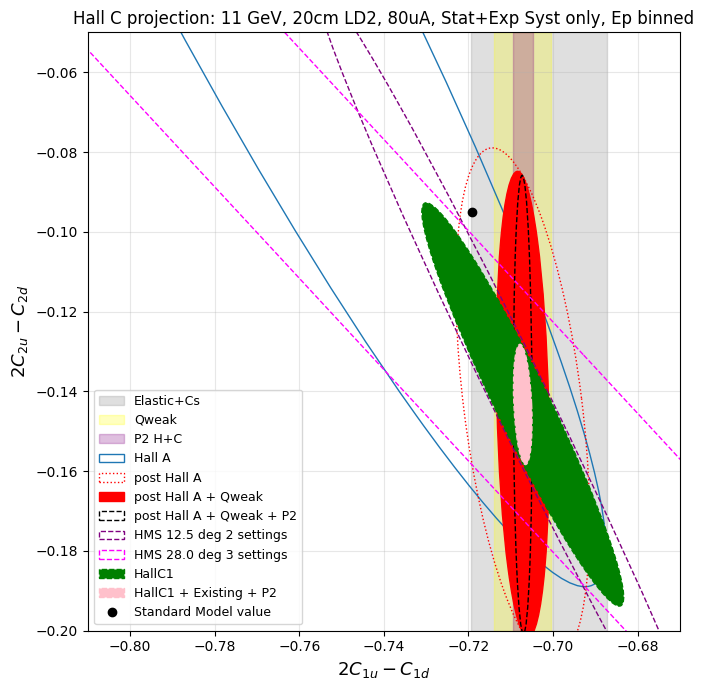

In [ ]:
# --------------------------------------------------
# Collect all fits to display
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 7))

ax.axvspan(
    X_el - X_el_err,
    X_el + X_el_err,
    color="gray",
    alpha=0.25,
    label=r"Elastic+Cs"
)

# ax.axvline(
#     X_el,
#     color="gray",
#     linestyle="--",
#     linewidth=1.5
# )

ax.axvspan(
    # X_qweak - X_qweak_err,
    # X_qweak + X_qweak_err,
    -0.70717 - X_qweak_err,
    -0.70717 + X_qweak_err,
    color="yellow",
    alpha=0.25,
    label=r"Qweak"
)

# ax.axvline(
#     X_qweak,
#     color="pink",
#     linestyle="--",
#     linewidth=1.5
# )

ax.axvspan(
    # X_p2 - X_p2_err,
    # X_p2 + X_p2_err,
    -0.70717 - X_p2_err,
    -0.70717 + X_p2_err,
    color="purple",
    alpha=0.25,
    label=r"P2 H+C"
)

# ax.axvline(
#     X_qweak,
#     color="purple",
#     linestyle="--",
#     linewidth=1.5
# )


results_to_plot = [
    (result_pvdis6, "Hall A", "tab:blue", False, "-"),
    (result_6gev, "post Hall A", "red", False, ":"),
    (result_6gev_qweak, "post Hall A + Qweak", "red", True, "-"),
    (result_6gev_qweak_p2, "post Hall A + Qweak + P2", "black", False, "--"),
    # (result_6gev_hrs,"HRS check (stat only)", "orange", "--"),
    (result_11gev_hms_loq,"HMS 12.5 deg 2 settings", "purple", False, "--"),
    (result_11gev_hms_hiq,"HMS 28.0 deg 3 settings", "magenta", False, "--"),
    # (result_11gev_hms1,f"HMS 12.5+28 deg setting 1 + {hallc_syst*100:.1f}% syst", "purple", False, "--"),
    # (result_11gev_hms2,f"HMS 12.5+28 deg setting 2 + {hallc_syst*100:.1f}% syst", "magenta", False, "--"),
    # (result_11gev_shms1,f"SHMS 12.5+28 deg setting 1 + {hallc_syst*100:.1f}% syst", "green", False, "--"),
    # (result_11gev_shms2,f"SHMS 12.5+28 deg setting 2 + {hallc_syst*100:.1f}% syst", "blue", False, "--"),
    # (result_11gev_hallc1,"HallC1", "cyan", True, "--"),
    # (result_11gev_hallc1_all,"HallC1 + Existing", "magenta", True, "--"),
    (result_11gev_hallc1,"HallC1", "green", True, "--"),
    (result_11gev_hallc1_all,"HallC1 + Existing + P2", "pink", True, "--"),
    # (result_11gev_hallc2_all,"HallC2 + Existing", "magenta", True, "-"),
    # (result_11gev_shms_loq,"SHMS 12.5 deg", "green", "-"),
    # (result_11gev_shms_hiq,"SHMS 28.0 deg", "cyan", "-"),
    # (result_11gev_solid,"SoLID11", "cyan", True, "--"),
    # (result_11gev_solid_all,"SoLID11 + Existing", "magenta", True, "--"),
    # (result_11gev_solid_2022,"SoLID11 (2022)", "cyan", False, "-"),
    # (result_11gev_solid_2022_all,"SoLID11 (2022) + Existing + P2", "magenta", False, "-"),
    # (result_11gev_solid_lite,"SoLID11 (Lite)", "cyan", False, "-"),
    # (result_11gev_solid_lite_all,"SoLID11 (Lite) + Existing + P2", "magenta", False, "-"),
]

confidence_levels = [0.683]

# --------------------------------------------------
# Overlay all fitted ellipses
# --------------------------------------------------
for result, fit_label, color, fill, line in results_to_plot:

    Xfit, Yfit = result["params"]
    cov = result["cov"]
    angle = result["angle_deg"]
    ellipses = result["ellipses"]

    # # Best-fit point
    # ax.plot(
    #     Xfit, Yfit,
    #     marker="o",
    #     color=color,
    #     linestyle="none",
    #     label=f"{fit_label}: best fit",
    #     zorder=4,
    # )

    for cl in confidence_levels:
        e = ellipses[cl]

        ellipse = Ellipse(
            xy=(Xfit, Yfit),
            width=2 * e["semi_major"],
            height=2 * e["semi_minor"],
            angle=angle,
            fill=fill,
            edgecolor=color,
            facecolor=color,
            linestyle=line,
            linewidth=1,
            # label=f"{fit_label}: {100*cl:g}%",
            label=f"{fit_label}",
            zorder=2,
        )
        ax.add_patch(ellipse)


# Standard Model point
ax.plot(
    c1q_SM, c2q_SM,
    marker="o",
    color="black",
    linestyle="none",
    label="Standard Model value",
    zorder=4,
)

# ax.set_xlim(-0.9,-0.4)
# ax.set_ylim(-0.5,0.25)

ax.set_xlim(-0.81,-0.67)
ax.set_ylim(-0.2,-0.05)

ax.set_xlabel(r"$2C_{1u}-C_{1d}$", fontsize=13)
ax.set_ylabel(r"$2C_{2u}-C_{2d}$", fontsize=13)
ax.set_title("Hall C projection: 11 GeV, 20cm LD2, 80uA, Stat+Exp Syst only, Ep binned")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)
ax.set_aspect("auto")

plt.tight_layout()
plt.show()

## 11 GeV Hall C C1,C2,betaHT,betaCSV fit

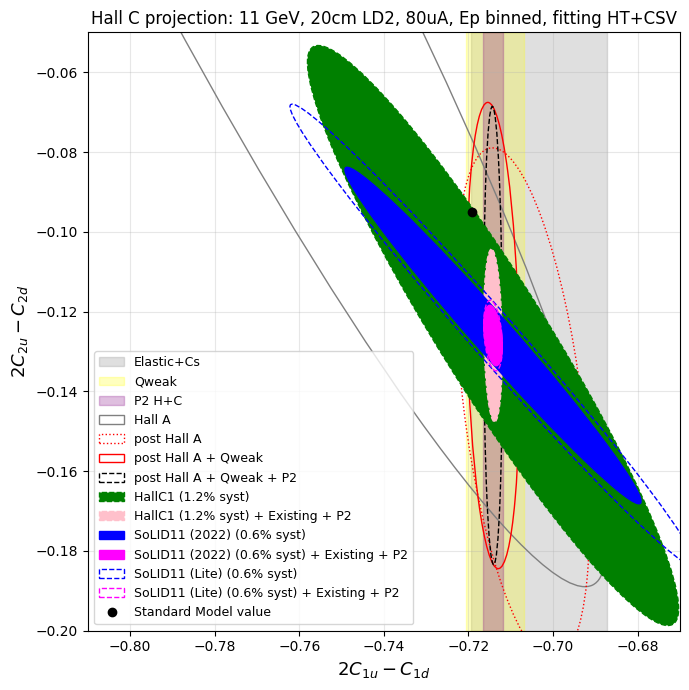

In [ ]:
# --------------------------------------------------
# Collect all fits to display
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 7))

ax.axvspan(
    X_el - X_el_err,
    X_el + X_el_err,
    color="gray",
    alpha=0.25,
    label=r"Elastic+Cs"
)

# ax.axvline(
#     X_el,
#     color="gray",
#     linestyle="--",
#     linewidth=1.5
# )

ax.axvspan(
    X_qweak - X_qweak_err,
    X_qweak + X_qweak_err,
    # -0.70717 - X_qweak_err,
    # -0.70717 + X_qweak_err,
    color="yellow",
    alpha=0.25,
    label=r"Qweak"
)

# ax.axvline(
#     X_qweak,
#     color="pink",
#     linestyle="--",
#     linewidth=1.5
# )

ax.axvspan(
    X_p2 - X_p2_err,
    X_p2 + X_p2_err,
    # -0.70717 - X_p2_err,
    # -0.70717 + X_p2_err,
    color="purple",
    alpha=0.25,
    label=r"P2 H+C"
)

# ax.axvline(
#     X_qweak,
#     color="purple",
#     linestyle="--",
#     linewidth=1.5
# )


# fit_type = "result1"
# Title = "Hall C projection: 11 GeV, 20cm LD2, 80uA, Ep binned"

# fit_type = "result2"
# Title = "Hall C projection: 11 GeV, 20cm LD2, 80uA, Ep binned, fitting HT"

# fit_type = "result3"  # Change to "result3" or "result4"
# Title = "Hall C projection: 11 GeV, 20cm LD2, 80uA, Ep binned, fitting CSV"

fit_type = "result4"  # Change to "result3" or "result4"
Title = "Hall C projection: 11 GeV, 20cm LD2, 80uA, Ep binned, fitting HT+CSV"

results_to_plot = [
    (result_pvdis6, "Hall A", "tab:blue", False, "-"),
    (result_6gev, "post Hall A", "red", False, ":"),
    (result_6gev_qweak, "post Hall A + Qweak", "red", True, "-"),
    (result_6gev_qweak_p2, "post Hall A + Qweak + P2", "black", False, "--"),

    (results[fit_type]["hallc1"], f"HallC1 ({hallc_syst*100:.1f}% syst)", "green", True, "--"),
    (results[fit_type]["hallc1_all"], f"HallC1 ({hallc_syst*100:.1f}% syst) + Existing + P2", "pink", True, "--"),
    (results[fit_type]["solid11"], f"SoLID11 ({solid11_syst*100:.1f}% syst)", "cyan", False, "--"),
    (results[fit_type]["solid11_all"], f"SoLID11 ({solid11_syst*100:.1f}% syst) + Existing + P2", "magenta", False, "--"),
    (results[fit_type]["solid11_2022"], f"SoLID11 (2022) ({solid11_syst*100:.1f}% syst)", "cyan", True, "--"),
    (results[fit_type]["solid11_2022_all"], f"SoLID11 (2022) ({solid11_syst*100:.1f}% syst) + Existing + P2", "magenta", True, "--"),
]

# for Hi-Lumi workshop
# Title = ""
results_to_plot = [
    (result_pvdis6, "Hall A", "grey", False, "-"),
    (result_6gev, "post Hall A", "red", False, ":"),
    (result_6gev_qweak, "post Hall A + Qweak", "red", False, "-"),
    (result_6gev_qweak_p2, "post Hall A + Qweak + P2", "black", False, "--"),

    (results[fit_type]["hallc1"], f"HallC1 ({hallc_syst*100:.1f}% syst)", "green", True, "--"),
    (results[fit_type]["hallc1_all"], f"HallC1 ({hallc_syst*100:.1f}% syst) + Existing + P2", "pink", True, "--"),
    # (results[fit_type]["solid11"], f"SoLID11 ({solid11_syst*100:.1f}% syst)", "cyan", False, "--"),
    # (results[fit_type]["solid11_all"], f"SoLID11 ({solid11_syst*100:.1f}% syst) + Existing + P2", "magenta", False, "--"),
    (results[fit_type]["solid11_2022"], f"SoLID11 (2022) ({solid11_syst*100:.1f}% syst)", "blue", True, "-"),
    (results[fit_type]["solid11_2022_all"], f"SoLID11 (2022) ({solid11_syst*100:.1f}% syst) + Existing + P2", "magenta", True, "-"),
    (results[fit_type]["solid11_lite"], f"SoLID11 (Lite) ({solid11_syst*100:.1f}% syst)", "blue", False, "--"),
    (results[fit_type]["solid11_lite_all"], f"SoLID11 (Lite) ({solid11_lite_syst*100:.1f}% syst) + Existing + P2", "magenta", False, "--"),
]

central_values_jens = np.array([-0.716, -0.126])
central_values_jens = np.array([X_p2, -0.126])

result_6gev_qweak["params"] = central_values_jens.copy()
result_6gev_qweak_p2["params"] = central_values_jens.copy()
results[fit_type]["hallc1"]["params"] = central_values_jens.copy()
results[fit_type]["hallc1_all"]["params"] = central_values_jens.copy()
results[fit_type]["solid11"]["params"] = central_values_jens.copy()
results[fit_type]["solid11_all"]["params"] = central_values_jens.copy()
results[fit_type]["solid11_2022"]["params"] = central_values_jens.copy()
results[fit_type]["solid11_2022_all"]["params"] = central_values_jens.copy()
results[fit_type]["solid11_lite"]["params"] = central_values_jens.copy()
results[fit_type]["solid11_lite_all"]["params"] = central_values_jens.copy()


confidence_levels = [0.683]

# --------------------------------------------------
# Overlay all fitted ellipses
# --------------------------------------------------
for result, fit_label, color, fill, line in results_to_plot:

    Xfit, Yfit = result["params"]
    cov = result["cov"]
    angle = result["angle_deg"]
    ellipses = result["ellipses"]

    # # Best-fit point
    # ax.plot(
    #     Xfit, Yfit,
    #     marker="o",
    #     color=color,
    #     linestyle="none",
    #     label=f"{fit_label}: best fit",
    #     zorder=4,
    # )

    for cl in confidence_levels:
        e = ellipses[cl]

        ellipse = Ellipse(
            xy=(Xfit, Yfit),
            width=2 * e["semi_major"],
            height=2 * e["semi_minor"],
            angle=angle,
            fill=fill,
            edgecolor=color,
            facecolor=color,
            linestyle=line,
            linewidth=1,
            # label=f"{fit_label}: {100*cl:g}%",
            label=f"{fit_label}",
            zorder=2,
        )
        ax.add_patch(ellipse)


# Standard Model point
ax.plot(
    c1q_SM, c2q_SM,
    marker="o",
    color="black",
    linestyle="none",
    label="Standard Model value",
    zorder=4,
)

# ax.set_xlim(-0.9,-0.4)
# ax.set_ylim(-0.5,0.25)

ax.set_xlim(-0.81,-0.67)
ax.set_ylim(-0.2,-0.05)

ax.set_xlabel(r"$2C_{1u}-C_{1d}$", fontsize=13)
ax.set_ylabel(r"$2C_{2u}-C_{2d}$", fontsize=13)
ax.set_title(Title)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)
ax.set_aspect("auto")

plt.tight_layout()
plt.show()

# Plot contours

In [ ]:
# translated from c1c2.kumac

# * see Jens' email (to jlab) on 8/1/2013
# *a) one contour for Prescott
# *b) one band for APV + Qweak
# *b) one contour for Prescott + APV + Qweak (previous knowledge)
# *c) one contour for PVDIS
# *d) one contour for all combined

import numpy as np
import matplotlib.pyplot as plt

contours = {
    "Prescott (Jens)": {
        "x": [
            -1.4785, -1.4139, -1.3301, -1.2404, -1.1465,
            -1.0489, -0.94716, -0.83930, -0.78090, -0.70480,
            -0.69994, -0.76448, -0.84829, -0.93802, -1.0319,
            -1.1295, -1.2313, -1.3391, -1.3975, -1.4736
        ],
        "y": [
            4.2557, 3.6761, 3.0988, 2.5226, 1.9470,
            1.3720, 0.79770, 0.22437, -0.061562, -0.34330,
            -0.31446, 0.26523, 0.84245, 1.4187, 1.9943,
            2.5693, 3.1436, 3.7169, 4.0028, 4.2846
        ],
        "color": 5,
    },

    "Hall A (Jens)": {
        "x": [
            -0.86790, -0.85700, -0.83972, -0.82017, -0.79894,
            -0.77612, -0.75172, -0.72473, -0.70944, -0.68973,
            -0.68463, -0.69562, -0.71280, -0.73239, -0.75360,
            -0.77645, -0.79456, -0.81392, -0.83523, -0.86281
        ],
        "y": [
            0.15456, 0.10625, 0.059840, 0.014450, -0.030179,
            -0.074111, -0.11719, -0.15900, -0.17887, -0.19437,
            -0.18439, -0.13610, -0.089659, -0.044287, 0.00035375,
            0.044361, 0.076822, 0.10856, 0.13929, 0.16455
        ],
        "color": 4,
    },

    "postHallA (Jens)": {
        "x": [
            -0.72273, -0.72152, -0.71824, -0.71579, -0.71263,
            -0.70828, -0.70515, -0.69997, -0.69435, -0.69258,
            -0.69160, -0.69281, -0.69609, -0.69854, -0.70170,
            -0.70606, -0.70918, -0.71436, -0.71998, -0.72175
        ],
        "y": [
            -0.11564, -0.14057, -0.16532, -0.17770, -0.18992,
            -0.20198, -0.20774, -0.21174, -0.20413, -0.19484,
            -0.17642, -0.15148, -0.12673, -0.11435, -0.10213,
            -0.090075, -0.084317, -0.080311, -0.087924, -0.097215
        ],
        "color": 2,
    },
}

In [ ]:
preHallA_contour = {
    "preHallA (Jens)": {
        "x": [
            -0.72010, -0.71931, -0.71695, -0.71256, -0.70898,
            -0.70633, -0.70005, -0.69390, -0.69177, -0.68945,
            -0.68803, -0.68883, -0.69119, -0.69557, -0.69916,
            -0.70181, -0.70808, -0.71423, -0.71636, -0.71869
        ],
        "y": [
            -0.19613, -0.31386, -0.43157, -0.54928, -0.60813,
            -0.63755, -0.66641, -0.63156, -0.59623, -0.52559,
            -0.38438, -0.26666, -0.14895, -0.031237, 0.027613,
            0.057030, 0.085893, 0.051039, 0.015709, -0.054925
        ],
        "color": 3,
    },
}

PVDIS_contour = {
    "PVDIS (Jens)": {
        "x": [
            -0.83073, -0.82464, -0.81406, -0.80146, -0.78737,
            -0.77184, -0.75478, -0.73536, -0.72396, -0.70881,
            -0.70281, -0.70891, -0.71948, -0.73208, -0.74618,
            -0.76170, -0.77877, -0.79819, -0.80959, -0.82473
        ],
        "y": [
            0.094611, 0.058502, 0.023443, -0.010874, -0.044603,
            -0.077833, -0.11030, -0.14174, -0.15652, -0.16744,
            -0.15391, -0.11780, -0.082742, -0.048426, -0.014696,
            0.018534, 0.051001, 0.082438, 0.097225, 0.10815
        ],
        "color": 6,
    },
}

# contours.update(preHallA_contour)
# contours.update(PVDIS_contour)

In [ ]:

solid_contours = {
    "SoLID (Jens)": {
        "x": [
            -0.743457, -0.737778, -0.732346, -0.726420, -0.720988,
            -0.715062, -0.707407, -0.700741, -0.694568, -0.690864,
            -0.689136, -0.695802, -0.701481, -0.706667, -0.714074,
            -0.721728, -0.728148, -0.732840, -0.737778, -0.741975,
        ],
        "y": [
            -0.0933200, -0.0963791, -0.101647, -0.107795, -0.113947,
            -0.120316, -0.129766, -0.138117, -0.146472, -0.152853,
            -0.157259, -0.153543, -0.148276, -0.142786, -0.134659,
            -0.125650, -0.117739, -0.111584, -0.104988, -0.0981683,
        ],
        "color": 7,
    },
    "SoLID + Existing (Jens)": {
        "x": [
            -0.717778, -0.716790, -0.715309, -0.714074, -0.713580,
            -0.713333, -0.714568, -0.716543, -0.717531, -0.717778,
        ],
        "y": [
            -0.121876, -0.120104, -0.121200, -0.123621, -0.126488,
            -0.130240, -0.132896, -0.130699, -0.127614, -0.124525,
        ],
        "color": 8,
    },
}

# Combine the dictionaries
contours.update(solid_contours)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import splprep, splev

def plot_contour_smooth(ax, contour, swap=False, n_points=300, **kwargs):
    x = np.asarray(contour["x"], dtype=float)
    y = np.asarray(contour["y"], dtype=float)

    if swap:
        x, y = y, x

    # Remove a duplicated endpoint if one is present
    if np.allclose([x[0], y[0]], [x[-1], y[-1]]):
        x = x[:-1]
        y = y[:-1]

    # Periodic cubic spline for a closed contour
    tck, u = splprep([x, y], s=0, per=True, k=3)

    u_fine = np.linspace(0, 1, n_points, endpoint=False)
    x_smooth, y_smooth = splev(u_fine, tck)

    ax.fill(x_smooth, y_smooth, **kwargs)

In [ ]:
def fit_ellipse_approx(x, y, scale=1.0):
    """
    Approximate a closed contour by an ellipse.

    Returns:
        center: (x0, y0)
        width, height: full axis lengths
        angle: ellipse rotation in degrees

    scale > 1 enlarges the ellipse; scale < 1 shrinks it.
    """
    points = np.column_stack([x, y])

    # Center the points
    center = points.mean(axis=0)
    centered = points - center

    # Principal axes from the point distribution
    cov = np.cov(centered.T)
    eigvals, eigvecs = np.linalg.eigh(cov)

    order = np.argsort(eigvals)[::-1]
    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]

    # Project points onto the principal axes
    projected = centered @ eigvecs

    # Choose semi-axes to encompass all supplied points
    semiaxes = np.max(np.abs(projected), axis=0) * scale

    angle = np.degrees(
        np.arctan2(eigvecs[1, 0], eigvecs[0, 0])
    )

    width, height = 2 * semiaxes

    return center, width, height, angle

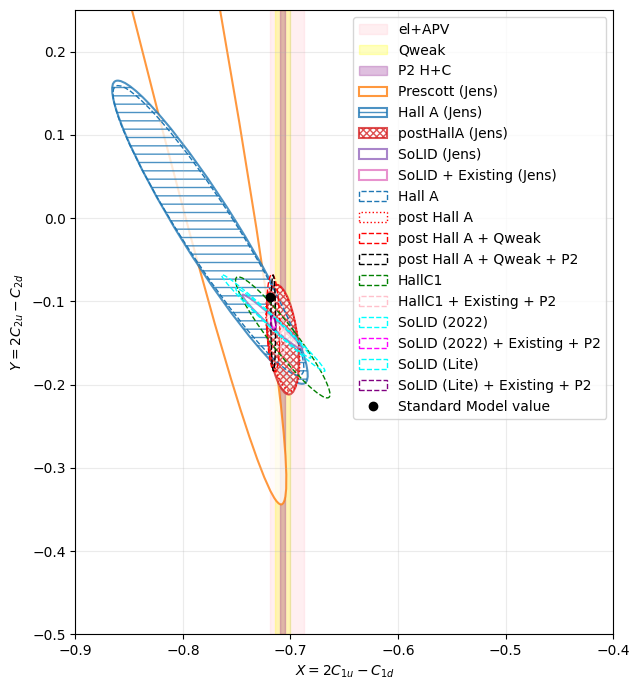

In [ ]:
def plot_contour(ax, contour, swap=False, **kwargs):
    x = np.asarray(contour["x"])
    y = np.asarray(contour["y"])

    if swap:
        x, y = y, x

    ax.fill(x, y, **kwargs)


# fig, ax = plt.subplots(figsize=(5.5, 7)) # to match SoLID proposal plot
fig, ax = plt.subplots(figsize=(6.5, 7))


ax.axvspan(
    X_el - X_el_err,
    X_el + X_el_err,
    color="pink",
    alpha=0.25,
    label=r"el+APV"
)

# ax.axvline(
#     X_el,
#     color="purple",
#     linestyle="--",
#     linewidth=1.5
# )


ax.axvspan(
    # X_qweak - X_qweak_err,
    # X_qweak + X_qweak_err,
    -0.70717 - X_qweak_err,
    -0.70717 + X_qweak_err,
    color="yellow",
    alpha=0.25,
    label=r"Qweak"
)

# ax.axvline(
#     X_qweak,
#     color="pink",
#     linestyle="--",
#     linewidth=1.5
# )

ax.axvspan(
    # X_p2 - X_p2_err,
    # X_p2 + X_p2_err,
    -0.70717 - X_p2_err,
    -0.70717 + X_p2_err,
    color="purple",
    alpha=0.25,
    label=r"P2 H+C"
)


# Fill colors can be chosen to match your desired plotting style.
# colors = {
#     "Prescott": "tab:orange",
#     "preHallA": "tab:green",
#     "Hall A": "tab:blue",
#     "PVDIS": "tab:yellow",
#     "postHallA": "tab:red",
# }

styles = {
    "Prescott (Jens)":  {"color": "tab:orange", "hatch": None},
    "preHallA (Jens)":  {"color": "tab:green", "hatch": "\\\\\\"},
    "Hall A (Jens)":    {"color": "tab:blue",  "hatch": "--"},
    "PVDIS (Jens)":     {"color": "tab:yellow", "hatch": "xx"},
    "postHallA (Jens)": {"color": "tab:red", "hatch": "xxxxx"},
    "SoLID (Jens)":     {"color": "tab:purple", "hatch": None},
    "SoLID + Existing (Jens)": {"color": "tab:pink", "hatch": None},
}

# for name, contour in contours.items():
#     plot_contour_smooth(
#         ax,
#         contour,
#         n_points=300,
#         facecolor=colors[name],
#         edgecolor=colors[name],
#         alpha=0.20,
#         linewidth=1.5,
#         label=name,
#     )
#     # plot_contour(
#     #     ax,
#     #     contour,
#     #     swap=False,
#     #     facecolor=colors[name],
#     #     edgecolor=colors[name],
#     #     alpha=0.20,
#     #     linewidth=1.5,
#     #     label=name,
#     # )


for name, contour in contours.items():
    x = np.asarray(contour["x"])
    y = np.asarray(contour["y"])

    center, width, height, angle = fit_ellipse_approx(x, y)

    style = styles[name]

    ellipse = Ellipse(
        xy=center,
        width=width,
        height=height,
        angle=angle,
        facecolor="white",
        edgecolor=style["color"],
        hatch=style["hatch"],
        alpha=0.8,
        linewidth=1.5,
        label=name,
    )

    ax.add_patch(ellipse)


# fit_type = "result1"
# Title = "Hall C projection: 11 GeV, 20cm LD2, 80uA, Ep binned"

# fit_type = "result2"
# Title = "Hall C projection: 11 GeV, 20cm LD2, 80uA, Ep binned, fitting HT"

# fit_type = "result3"  # Change to "result3" or "result4"
# Title = "Hall C projection: 11 GeV, 20cm LD2, 80uA, Ep binned, fitting CSV"

fit_type = "result4"  # Change to "result3" or "result4"
Title = "Hall C projection: 11 GeV, 20cm LD2, 80uA, Ep binned, fitting HT+CSV"

results_to_plot = [
    (result_pvdis6, "Hall A", "tab:blue", False, "--"),
    (result_6gev, "post Hall A", "red", False, ":"),
    (result_6gev_qweak, "post Hall A + Qweak", "red", False, "--"),
    (result_6gev_qweak_p2, "post Hall A + Qweak + P2", "black", False, "--"),

    (results[fit_type]["hallc1"], "HallC1", "green", False, "--"),
    (results[fit_type]["hallc1_all"], "HallC1 + Existing + P2", "pink", False, "--"),

    # (results[fit_type]["solid11"], "SoLID", "cyan", False, "--"),
    # (results[fit_type]["solid11_all"], "SoLID + Existing + P2", "magenta", False, "--"),

    (results[fit_type]["solid11_2022"], "SoLID (2022)", "cyan", False, "--"),
    (results[fit_type]["solid11_2022_all"], "SoLID (2022) + Existing + P2", "magenta", False, "--"),
    (results[fit_type]["solid11_lite"], "SoLID (Lite)", "cyan", False, "--"),
    (results[fit_type]["solid11_lite_all"], "SoLID (Lite) + Existing + P2", "purple", False, "--"),
]

confidence_levels = [0.683]

# --------------------------------------------------
# Overlay all fitted ellipses
# --------------------------------------------------
for result, fit_label, color, fill, line in results_to_plot:

    Xfit, Yfit = result["params"]
    cov = result["cov"]
    angle = result["angle_deg"]
    ellipses = result["ellipses"]

    for cl in confidence_levels:
        e = ellipses[cl]

        ellipse = Ellipse(
            xy=(Xfit, Yfit),
            width=2 * e["semi_major"],
            height=2 * e["semi_minor"],
            angle=angle,
            fill=fill,
            edgecolor=color,
            facecolor=color,
            linestyle=line,
            linewidth=1,
            # label=f"{fit_label}: {100*cl:g}%",
            label=f"{fit_label}",
            zorder=2,
        )
        ax.add_patch(ellipse)


# Standard Model point
ax.plot(
    c1q_SM, c2q_SM,
    marker="o",
    color="black",
    linestyle="none",
    label="Standard Model value",
    zorder=4,
)

ax.set_xlim(-0.9,-0.4) # match Nature paper
ax.set_ylim(-0.5,0.25)

# ax.set_xlim(-0.77,-0.67) # match SoLID proposal
# ax.set_ylim(-0.20,-0.05)

# ax.set_xlim(-0.79,-0.67) # expand in X
# ax.set_ylim(-0.20,-0.05)



ax.set_xlabel(r"$X = 2C_{1u}-C_{1d}$")
ax.set_ylabel(r"$Y = 2C_{2u}-C_{2d}$")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

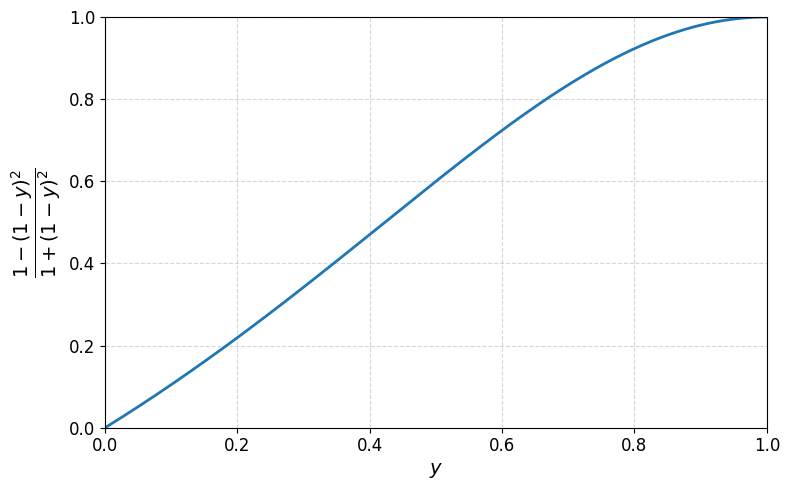

In [ ]:
# Define y and the function
y = np.linspace(0.0, 1.0, 500)
f = (1.0 - (1.0 - y)**2) / (1.0 + (1.0 - y)**2)

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(y, f, color="tab:blue", linewidth=2)

ax.set_xlabel(r"$y$", fontsize=14)
ax.set_ylabel(r"$\dfrac{1-(1-y)^2}{1+(1-y)^2}$", fontsize=14)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.set_yticks(np.arange(0, 1.01, 0.2))

ax.grid(True, linestyle="--", alpha=0.5)
ax.tick_params(axis="both", labelsize=12)

plt.tight_layout()
plt.show()